# Figure S25 - Sampling quality versus temperature for a GCN4 fragment

Lotthammer, J. M. & Holehouse, A. S. *Disentangling folding from energetic traps in simulations of disordered proteins.* **J. Chem. Inf. Model.** (2025). doi:[10.1021/acs.jcim.4c02005](https://doi.org/10.1021/acs.jcim.4c02005)

**What the figure shows.** A transiently helical 20-residue fragment of yeast GCN4 simulated at ten temperatures from 150 K to 400 K. Panel A is a heat map of the *standard deviation across replicates* of the per-residue EV-comparison Hellinger distance; panel B is the replicate-mean fractional helicity. Both are plotted as temperature x residue.

**What to look for.** At low temperature the replicates disagree with one another (large standard deviation) - the chain is kinetically trapped and each replicate sees a different local minimum. Raising the temperature shrinks the spread, but by ~330 K the transient helix around residues 4-12 has melted away (panel B). The take-home is that temperature is a blunt instrument: it improves sampling by flattening the landscape, and in doing so it can erase the very structure you wanted to characterise.

**Data.** 15 coil-start FH replicates (3000 frames) at each temperature, all compared against the 15 EV replicates run at 270 K (the EV reference has no temperature-dependent interactions to speak of, so one reference serves all temperatures). This notebook builds ten `SamplingQuality` objects, so it takes a few minutes.

## Setup

All notebooks in this directory share `penguin_helpers.py`, a thin layer over SOURSOP's public `soursop.sssampling.SamplingQuality` API that handles data discovery, the manuscript's matplotlib style, and the four-panel PENGUIN figure. The trajectories (~6 GB) live in `data/`, one folder per system with `full/` and `ev/` replicates (see `data/README.md`); they are too large for the SOURSOP repository, so set `PENGUIN_DATA_DIR` if you keep them elsewhere.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from penguin_helpers import (
    set_manuscript_style, get_data_dir, figure_path, load_system,
    penguin_figure, print_sequence,
)

set_manuscript_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

DATA_DIR = get_data_dir()
print("Reading simulation data from", DATA_DIR)

Reading simulation data from /Users/alex/Dropbox/WASHU/Holehouse/tools/soursop/soursop/demo_examples/penguin/data


## Build one SamplingQuality per temperature

In [2]:
from soursop.sssampling import SamplingQuality
from soursop.sstools import find_trajectory_files

temperatures = ["150K", "200K", "250K", "300K", "310K", "320K", "330K", "340K", "350K", "400K"]

ev_trj, ev_top = find_trajectory_files(DATA_DIR / "gcn4" / "ev", 15)

quals = {}
for T in temperatures:
    trj, top = find_trajectory_files(DATA_DIR / "gcn4" / T, 15)
    quals[T] = SamplingQuality(trj, ev_trj, top_file=top[0], ref_top=ev_top[0],
                               method="2D angle distributions", seed=0, verbose=False)
    print(f"{T}: {len(trj)} replicates")
sequence = print_sequence(quals["300K"])

150K: 15 replicates


200K: 15 replicates


250K: 15 replicates


300K: 15 replicates


310K: 15 replicates


320K: 15 replicates


330K: 15 replicates


340K: 15 replicates


350K: 15 replicates


400K: 15 replicates
NLEDNSKEWTSLFDNDIPVT
.........1.........2


## Collect the per-temperature summaries

In [3]:
hellingers = np.array([np.asarray(quals[T].hellingers_distances()) for T in temperatures])   # (T, reps, res)
helicity = np.array([np.asarray(quals[T].fractional_helicity()[0]) for T in temperatures])       # (T, reps, res)

hellingers_std = hellingers.std(axis=1)     # spread across replicates
mean_helicity = helicity.mean(axis=1)
print("shapes:", hellingers_std.shape, mean_helicity.shape)

shapes: (10, 20) (10, 20)


## Plot

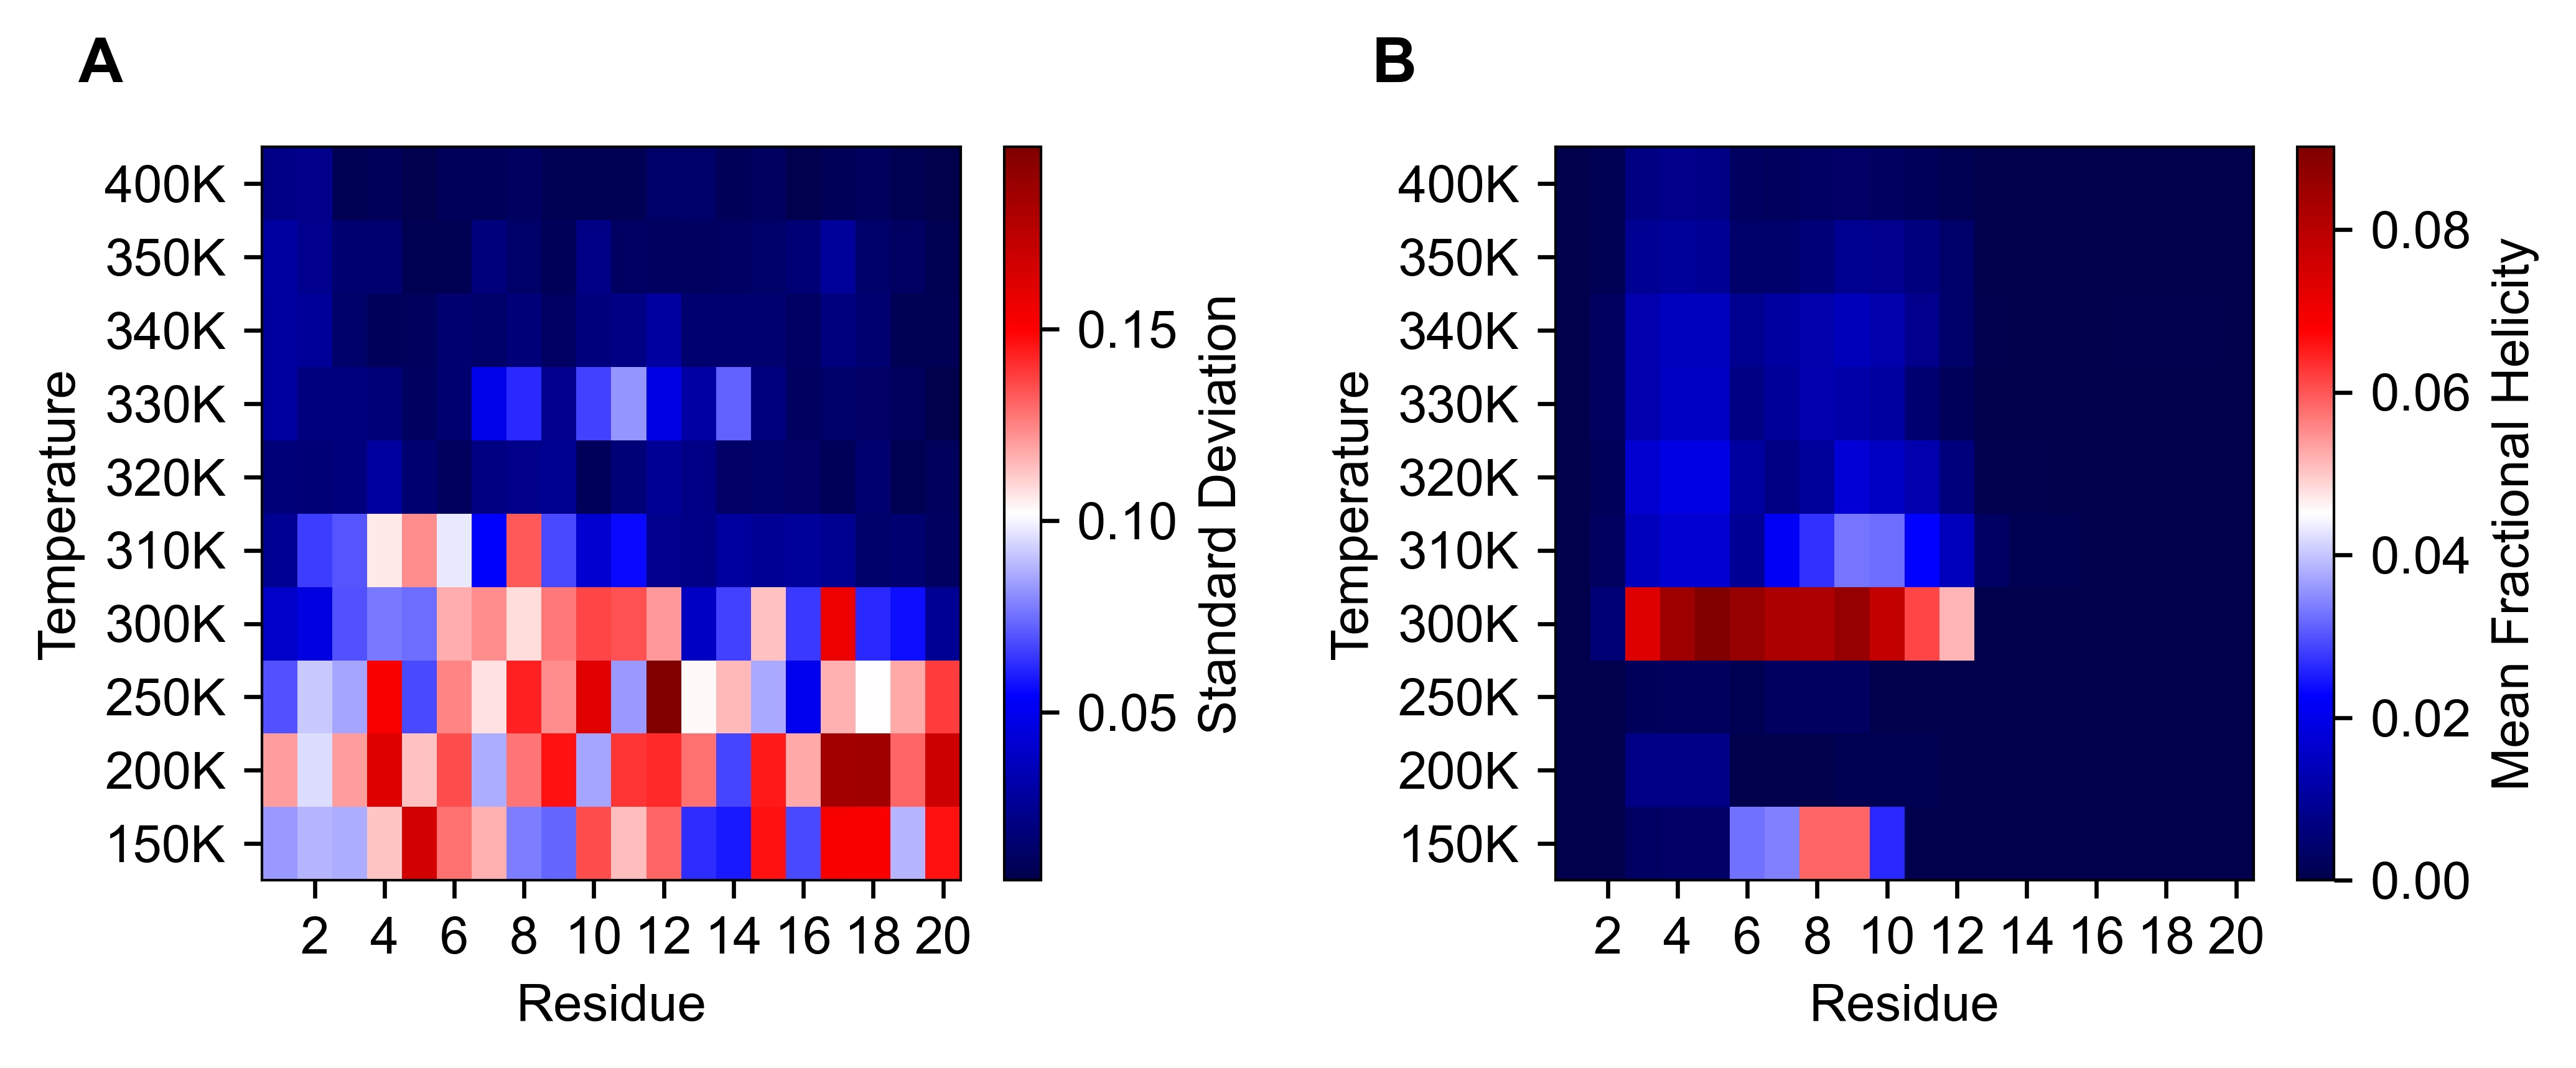

In [4]:
import matplotlib.transforms as mtransforms

fontsize = 10
n_res = hellingers_std.shape[1]
fig, axes = plt.subplots(1, 2, figsize=(7, 3), facecolor="w", dpi=300)

x_ticks = np.arange(1, n_res, 2) + 0.5
x_ticklabels = np.arange(2, n_res + 2, 2)
y_ticks = 0.5 + np.arange(len(temperatures))

for ax, data, label, cbar_label in [(axes[0], hellingers_std, "A", "Standard Deviation"),
                                    (axes[1], mean_helicity, "B", "Mean Fractional Helicity")]:
    mesh = ax.pcolormesh(data, cmap="seismic")
    fig.colorbar(mesh, label=cbar_label, ax=ax)
    ax.set_xticks(x_ticks); ax.set_xticklabels(x_ticklabels, fontsize=fontsize)
    ax.set_yticks(y_ticks); ax.set_yticklabels(temperatures, fontsize=fontsize)
    ax.set_xlabel("Residue"); ax.set_ylabel("Temperature")
    trans = mtransforms.ScaledTranslation(-20 / 72, 7 / 72, fig.dpi_scale_trans)
    ax.text(-0.05, 1.10, label, transform=ax.transAxes + trans,
            fontsize=12, fontweight="bold", va="top", ha="right")

fig.tight_layout()
fig.savefig(figure_path("si_figures", "GCN4_2D_hellingers_std_vs_temp.pdf"), dpi=400)